Name : Luqman Khan

SID : S202266054

Section : V1

Course Code: CS4152

Semester: Fall 2026

Sumitted to: Dr. Jameel Ahmad

Course Title: Deep Learning and Neural Networks

##                                                          # TASK : 03

In [2]:
sns.set_theme(style='whitegrid')

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

Part a) Dataset **Preparation**

Generate a 2D nonlinear multi-cluster dataset with 4 classes

In [4]:
X, y = make_blobs(
    n_samples=1000,
    n_features=2,
    centers=4,
    cluster_std=1.2,
    random_state=42
)

80/20 train-validation split

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Visualizing dataset

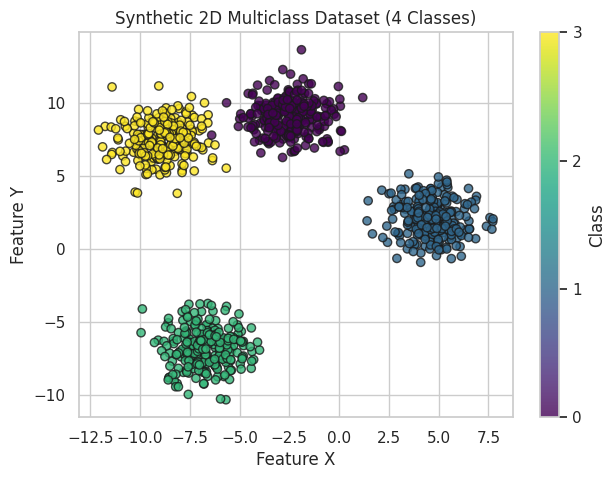

In [6]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.8)
plt.title("Synthetic 2D Multiclass Dataset (4 Classes)")
plt.xlabel("Feature X")
plt.ylabel("Feature Y")
plt.colorbar(scatter, ticks=range(4), label="Class")
plt.show()

# Part b) Network Architecture

In [9]:
model = Sequential([
    Dense(128, activation='relu', input_dim=2),     # Hidden layer with 128 units
    Dense(4, activation='softmax')                   # Output layer: 4 classes with softmax
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 900 (3.52 KB)

 Trainable params: 900 (3.52 KB)

 Non-trainable params: 0 (0.00 B)

# Part c) Model Compilation and Training

In [12]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Train for 40 epochs with batch size 10 and validation split / validation data

In [13]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=10,
    verbose=1
)

Epoch 1/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9225 - loss: 0.4110 - val_accuracy: 1.0000 - val_loss: 0.0907
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9987 - loss: 0.0656 - val_accuracy: 1.0000 - val_loss: 0.0382
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9975 - loss: 0.0350 - val_accuracy: 1.0000 - val_loss: 0.0241
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9987 - loss: 0.0243 - val_accuracy: 1.0000 - val_loss: 0.0164
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9975 - loss: 0.0188 - val_accuracy: 1.0000 - val_loss: 0.0135
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9975 - loss: 0.0165 - val_accuracy: 1.0000 - val_loss: 0.0102
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9975 - loss: 0.0136 - val_accuracy: 1.0000 - val_loss: 0.0084
Epoch 8/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9975 - loss: 0.0132 - val_accuracy: 1.0000 - val_loss:

# Part d) Model Evaluation

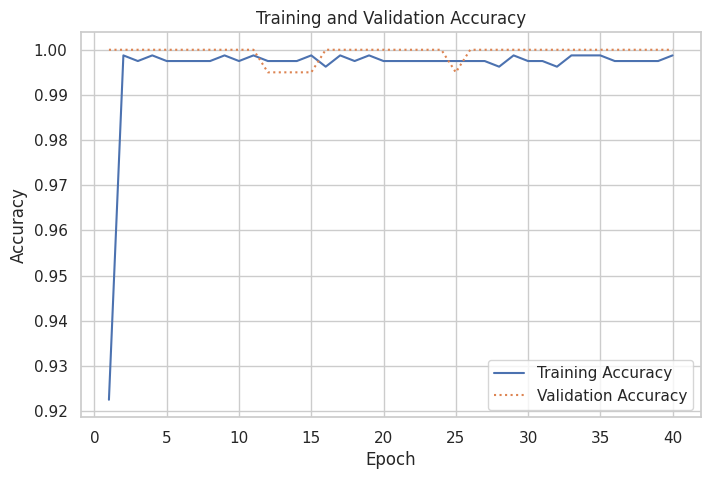

In [14]:
epochs_range = range(1, len(history.history['accuracy']) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history['accuracy'], '-', label='Training Accuracy')
plt.plot(epochs_range, history.history['val_accuracy'], ':', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()

2. Test Point Inference: point (0.2, 0.8)

In [15]:
test_point = np.array([[0.2, 0.8]])
probs = model.predict(test_point)
predicted_class = np.argmax(probs, axis=1)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


In [16]:
print(f"\nPrediction for test point (0.2, 0.8):")
print(f"Predicted Probability Distribution: {probs[0]}")
print(f"Predicted Class (using argmax): {predicted_class}")


Prediction for test point (0.2, 0.8):
Predicted Probability Distribution: [0.1464081  0.78997755 0.04220425 0.02141012]
Predicted Class (using argmax): 1


3. 2D Decision Boundary Visualization

In [17]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

Predict on grid

In [18]:
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_preds = np.argmax(model.predict(grid_points), axis=1)
grid_preds = grid_preds.reshape(xx.shape)

7102/7102 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step


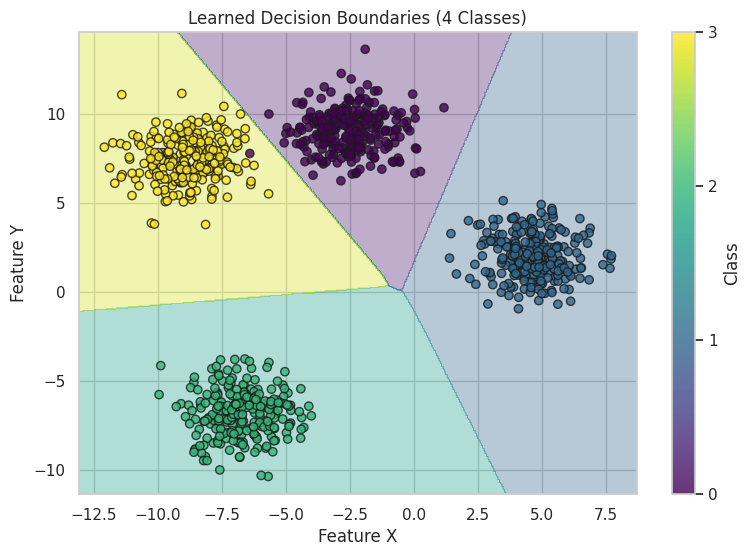

In [19]:
plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, grid_preds, alpha=0.35, cmap='viridis')
scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.8)
plt.title("Learned Decision Boundaries (4 Classes)")
plt.xlabel("Feature X")
plt.ylabel("Feature Y")
plt.colorbar(scatter, ticks=range(4), label="Class")
plt.show()

# Part e) Analysis & Confusion Matrix

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step 


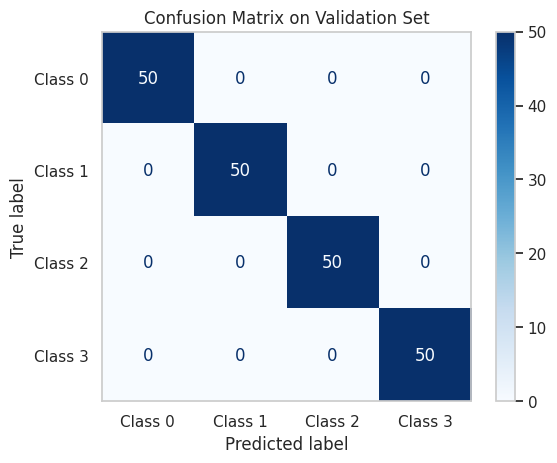

In [20]:
val_preds = np.argmax(model.predict(X_val), axis=1)

# Confusion Matrix
cm = confusion_matrix(y_val, val_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[f"Class {i}" for i in range(4)])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix on Validation Set")
plt.grid(False)
plt.show()

# Per-class classification metrics

In [21]:
print("\nClassification Report (Per-Class Accuracy, Precision, Recall):")
print(classification_report(y_val, val_preds, target_names=[f"Class {i}" for i in range(4)]))


Classification Report (Per-Class Accuracy, Precision, Recall):
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00        50
     Class 1       1.00      1.00      1.00        50
     Class 2       1.00      1.00      1.00        50
     Class 3       1.00      1.00      1.00        50

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



#Written Analysis & Theoretical Justifications

# 1. Why Softmax is Essential for Multiclass Classification
Probability Normalization: Unlike activations that produce unconstrained logits or independent single-class outputs (like standard Sigmoid), the Softmax activation function exponentiates each output neuron's logit and divides it by the sum of all exponentiated logits:
   $$\text{Softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{C} e^{z_j}}
#Mutually Exclusive Classes:
    This ensures every output value lies within the range $(0, 1)$ and all values strictly sum to $1.0$, creating a valid probability distribution across mutually exclusive class categories.   Alignment with Loss Function: Softmax couples directly with sparse_categorical_crossentropy (log loss), which applies exponential penalties to low predicted probabilities for the ground truth class.  
# 2. Difficulty in Classification by ClassClasses
     whose clusters are centrally located or overlap along decision boundaries exhibit lower recall and precision than peripheral, cleanly separable clusters.In typical 2D nonlinear cluster sets, boundary points with overlapping distributions yield flatter probability vectors (e.g., probabilities split between two classes like $\sim 0.48$ and $\sim 0.51$), resulting in borderline classifications.
#     #3. Architectural Modifications to Improve Performance
        Add Network Depth: Incorporate a second hidden layer (e.g., $128 \rightarrow 64$ neurons) to let the network capture higher-order nonlinear feature interactions.   Tune Hidden Width: Increase capacity if underfitting, or use regularizers such as Dropout (as explored in Task 4) to constrain overfitting along boundary edges.   Feature Engineering: Apply non-linear polynomial features or standardize raw inputs (StandardScaler) so the optimizer navigates the loss surface more efficiently.